# The floating LCLC box

An alternating series loop of $C_1$, $L_2$, $C_2$, $L_1$ with no node grounded.
It has no junctions, so the one retained mode is harmonic, and the example isolates the reduction of the
non-dynamical modes: each matrix is shown before and after the decoupling transformation.
Each step follows the notes; equation labels are given in comments.
The grounded box is worked in `Notes/driven_lclc_example.md`; floating adds one cyclic mode.

In [1]:
import sympy as sym
import circuit_quantization as cq
from circuit_quantization import Branch, Circuit, Loops, quantize

sym.init_printing()

In [2]:
C1, C2, L1, L2 = sym.symbols("C_1 C_2 L_1 L_2", positive=True)
circuit = Circuit([
    Branch("C1", 1, 2, C=C1),
    Branch("C2", 3, 4, C=C2),
    Branch("L1", 1, 3, L=L1),
    Branch("L2", 2, 4, L=L2),
])  # floating: no ground
loops = Loops.from_branch_dict(circuit, {"box": ("C1", "L2", "C2", "L1")})  # first branch fixes the orientation
loops.G, loops.Phi_ext

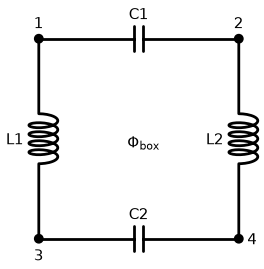

In [3]:
cq.draw_circuit_diagram(
    circuit, layout={1: (0, 1), 2: (1, 1), 3: (0, 0), 4: (1, 0)},
    flux_labels={r"$\Phi_{\rm box}$": (0.5, 0.5)},
)

## Lagrangian matrices

All four nodes are internal. Inductors carry no capacitance, so $C_b$ has zeros on the inductor branches.

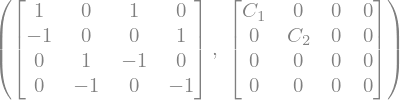

In [4]:
lag = cq.lagrangian(circuit)
lag.Omega_int, lag.C_b  # branch order C1, C2, L1, L2; eq:Cb_diag

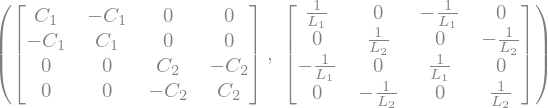

In [5]:
lag.C_int, lag.Lstar_int  # eq:C_full_partition, eq:L_full_partition

## Mode basis

`mode_basis` splits node space into the subspaces of the notes (eq:Z_mode_blocks):
a harmonic mode, a free mode in $N(L^*_{\rm int})$ (each inductor's two nodes move together),
a frozen mode in $N(C_{\rm int})$ (each capacitor's two nodes move together),
and a cyclic mode, the uniform shift of a floating circuit, in both.

In [6]:
Z, types = cq.mode_basis(lag)
Z, types

(Matrix([
 [ 1, -1, -1, 1],
 [-1,  1, -1, 1],
 [-1, -1,  1, 1],
 [ 1,  1,  1, 1]]),
 ('h', 'fr', 'fz', 'cy'))

### Before decoupling

In this basis $\tilde C = Z^T C_{\rm int} Z$ couples the harmonic mode to the free mode, and
$\tilde L^* = Z^T L^*_{\rm int} Z$ couples it to the frozen mode. The cyclic column is zero in both.

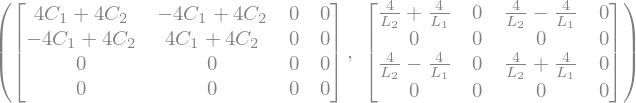

In [7]:
C_t = Z.T * lag.C_int * Z
L_t = Z.T * lag.Lstar_int * Z
C_t, L_t

## Decoupling

With the harmonic mode as block 1, the free and frozen modes are decoupled by
$M_C = -\tilde C_{22}^{-1}\tilde C_{21}$ (eq:decouple_final) and
$M_L = -(\tilde L^*_{22})^{-1}\tilde L^*_{21}$ (eq:decouple_final_L), each in its own block,
and $Z_{\rm dc} = Z Y_C Y_L$ (eq:ZY_blocks). The cyclic mode couples to nothing and needs no decoupling.

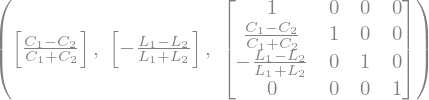

In [8]:
h, fr, fz = types.index("h"), types.index("fr"), types.index("fz")
M_C = (-C_t.extract([fr], [fr]).inv() * C_t.extract([fr], [h])).applyfunc(sym.factor)
M_L = (-L_t.extract([fz], [fz]).inv() * L_t.extract([fz], [h])).applyfunc(sym.factor)
Y_C, Y_L = sym.eye(4), sym.eye(4)
Y_C[fr, h] = M_C[0, 0]
Y_L[fz, h] = M_L[0, 0]
M_C, M_L, Y_C * Y_L

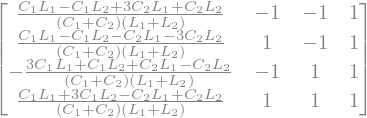

In [9]:
Z_dc = (Z * Y_C * Y_L).applyfunc(sym.factor)
coords = cq.decouple(lag, Z, types)
assert (Z_dc - coords.Z_full).applyfunc(sym.cancel).is_zero_matrix  # the package agrees
Z_dc

### After decoupling

Both quadratic forms are block diagonal. The harmonic entries are the Schur complements of the free block in
$\tilde C$ and of the frozen block in $\tilde L^*$ (eq:Zd_schur): the two capacitors and the two inductors in series.

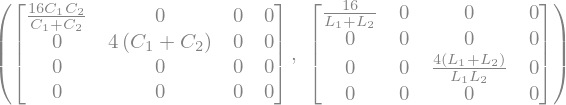

In [10]:
(Z_dc.T * lag.C_int * Z_dc).applyfunc(sym.factor), (Z_dc.T * lag.Lstar_int * Z_dc).applyfunc(sym.factor)

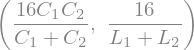

In [11]:
schur = lambda A, k, d: sym.factor((A.extract([k], [k]) - A.extract([k], [d]) * A.extract([d], [d]).inv() * A.extract([d], [k]))[0])
schur(C_t, h, fr), schur(L_t, h, fz)

## Truncation

Keep the harmonic column of $Z_{\rm dc}$ and the matching row $R$ of $Z_{\rm dc}^{-1}$ (eq:Z_truncated).

In [12]:
coords.types, coords.Z, coords.R, coords.C_tilde, coords.Lstar_tilde

(('h',),
 Matrix([
 [ (C_1*L_1 - C_1*L_2 + 3*C_2*L_1 + C_2*L_2)/(C_1*L_1 + C_1*L_2 + C_2*L_1 + C_2*L_2)],
 [ (C_1*L_1 - C_1*L_2 - C_2*L_1 - 3*C_2*L_2)/(C_1*L_1 + C_1*L_2 + C_2*L_1 + C_2*L_2)],
 [(-3*C_1*L_1 - C_1*L_2 - C_2*L_1 + C_2*L_2)/(C_1*L_1 + C_1*L_2 + C_2*L_1 + C_2*L_2)],
 [ (C_1*L_1 + 3*C_1*L_2 - C_2*L_1 + C_2*L_2)/(C_1*L_1 + C_1*L_2 + C_2*L_1 + C_2*L_2)]]),
 Matrix([[1/4, -1/4, -1/4, 1/4]]),
 Matrix([[16*C_1*C_2/(C_1 + C_2)]]),
 Matrix([[16/(L_1 + L_2)]]))

## Flux assignment and Hamiltonian

The loop is capacitively broken, and the inductors $L_1$, $L_2$ share no node, so there is no superconducting loop.
The irrotational $B$ (eq:B_irrot_direct_closed) satisfies the loop constraint $G B = 1$ and the
irrotational condition $Z^T \Omega_{\rm int} C_b B = 0$ (eq:irrotational_expanded).

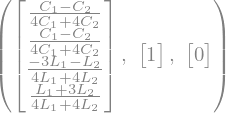

In [13]:
res = quantize(circuit, loops, simplify=True)
B = res.B
B, (loops.G * B).applyfunc(sym.cancel), (res.coords.Z.T * lag.Omega_int * lag.C_b * B).applyfunc(sym.cancel)

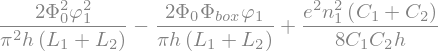

In [14]:
res.H  # the flux enters only as a displacement of the oscillator; no dPhi/dt term

### Rescaling the retained mode

The residual freedom of a single harmonic mode is a real scale, $S_1 = (s)$.
With $s = 1/4$ the retained coordinate becomes $\varphi_1 - \varphi_2 - \varphi_3 + \varphi_4$, the signed
sum of the two capacitor fluxes around the loop, and $\tilde C$, $\tilde L^*$ become the series values
$C_1 C_2/(C_1 + C_2)$ and $1/(L_1 + L_2)$.

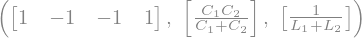

In [15]:
res_s = res.transform(sym.Matrix([[sym.Rational(1, 4)]]), simplify=True)
res_s.coords.R, res_s.coords.C_tilde, res_s.coords.Lstar_tilde

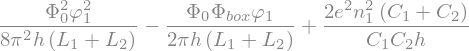

In [16]:
res_s.H